In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set the chart style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
from pathlib import Path
import pandas as pd

# Locate the existing dataset
file_path = Path("supermarket_ai_data.csv")

# Check whether the file exists
print("File exists:", file_path.exists())

# Load the dataset
if file_path.exists():
    df = pd.read_csv(file_path)

    print("Dataset loaded successfully!")
    print("Dataset shape:", df.shape)

    display(df.head())

File exists: True
Dataset loaded successfully!
Dataset shape: (10000, 28)


,Date,City,Country,Customer Type,Gender,Product Category,Product,SKU,Unit Cost,Sales Price,...,Calculated Profit,Profit Difference,Revenue After Discount,Discount Difference,Calculated COGS,COGS Difference,Gross Sales,Discount Percentage,Revenue Reduction,Reduction Difference
0,2024-06-29,Seattle,USA,Normal,Male,Groceries,Coffee (200g),1033,250,325,...,450.0,0.0,1850.00,100.00,1500,0,1950,5.128205,0.0,-100.00
1,2024-06-29,Sheffield,UK,Member,Male,Groceries,Fruits,1024,80,104,...,216.0,0.0,842.40,93.60,720,0,936,10.000000,0.0,-93.60
2,2024-06-29,Kanpur,India,Normal,Female,Personal Care,Shampoo,1051,180,234,...,54.0,0.0,217.62,16.38,180,0,234,7.000000,0.0,-16.38
3,2024-06-29,Raichur,India,Normal,Male,Groceries,Energy Drink,1034,100,130,...,140.0,0.0,868.00,-28.00,700,0,910,4.615385,70.0,28.00
4,2024-06-29,Milwaukee,USA,Normal,Male,Groceries,Bread,1022,40,52,...,36.0,0.0,148.20,7.80,120,0,156,5.000000,0.0,-7.80


In [3]:
import pandas as pd

# Path to the cleaned dataset
file_path = "../data/processed/supermarket_ai_data.csv"

# Load the cleaned dataset
df = pd.read_csv(file_path)

print("Cleaned dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Cleaned dataset loaded successfully!
Dataset shape: (10000, 28)


,Date,City,Country,Customer Type,Gender,Product Category,Product,SKU,Unit Cost,Sales Price,...,Calculated Profit,Profit Difference,Revenue After Discount,Discount Difference,Calculated COGS,COGS Difference,Gross Sales,Discount Percentage,Revenue Reduction,Reduction Difference
0,2024-06-29,Seattle,USA,Normal,Male,Groceries,Coffee (200g),1033,250,325,...,450.0,0.0,1850.00,100.00,1500,0,1950,5.128205,0.0,-100.00
1,2024-06-29,Sheffield,UK,Member,Male,Groceries,Fruits,1024,80,104,...,216.0,0.0,842.40,93.60,720,0,936,10.000000,0.0,-93.60
2,2024-06-29,Kanpur,India,Normal,Female,Personal Care,Shampoo,1051,180,234,...,54.0,0.0,217.62,16.38,180,0,234,7.000000,0.0,-16.38
3,2024-06-29,Raichur,India,Normal,Male,Groceries,Energy Drink,1034,100,130,...,140.0,0.0,868.00,-28.00,700,0,910,4.615385,70.0,28.00
4,2024-06-29,Milwaukee,USA,Normal,Male,Groceries,Bread,1022,40,52,...,36.0,0.0,148.20,7.80,120,0,156,5.000000,0.0,-7.80


In [4]:
# Convert Date to datetime format
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Ensure Revenue is numeric
df["Revenue"] = pd.to_numeric(df["Revenue"], errors="coerce")

# Check the results
print("Date data type:", df["Date"].dtype)
print("Revenue data type:", df["Revenue"].dtype)

print("\nMissing dates:", df["Date"].isna().sum())
print("Missing revenue:", df["Revenue"].isna().sum())

Date data type: datetime64[us]
Revenue data type: float64

Missing dates: 0
Missing revenue: 0


In [5]:
# Group revenue by month
monthly_revenue = (
    df.dropna(subset=["Date", "Revenue"])
      .groupby(df["Date"].dt.to_period("M"))["Revenue"]
      .sum()
)

# Display monthly revenue
monthly_revenue

Date
2024-06     2085204.50
2024-07    18309178.45
2024-08    16649314.80
2024-09    14390285.00
2024-10    16882830.20
2024-11    17632250.30
2024-12    18142849.50
2025-01    18857375.75
2025-02    17820200.45
2025-03    17890490.65
2025-04    19562347.50
2025-05    14292550.35
2025-06    13695102.45
Freq: M, Name: Revenue, dtype: float64

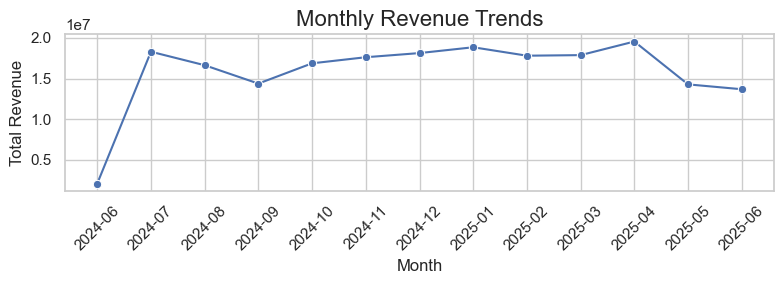

In [6]:
plt.figure(figsize=(8, 3))

sns.lineplot(
    x=monthly_revenue.index.astype(str),
    y=monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Revenue Trends", fontsize=16)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Revenue", fontsize=12)

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [7]:
# Display the exact monthly revenue values
print(monthly_revenue)

# Check the total of all monthly revenue values
print("\nTotal monthly revenue:", monthly_revenue.sum())

# Check the overall maximum and minimum
print("\nHighest monthly revenue:", monthly_revenue.max())
print("Lowest monthly revenue:", monthly_revenue.min())

Date
2024-06     2085204.50
2024-07    18309178.45
2024-08    16649314.80
2024-09    14390285.00
2024-10    16882830.20
2024-11    17632250.30
2024-12    18142849.50
2025-01    18857375.75
2025-02    17820200.45
2025-03    17890490.65
2025-04    19562347.50
2025-05    14292550.35
2025-06    13695102.45
Freq: M, Name: Revenue, dtype: float64

Total monthly revenue: 206209979.89999998

Highest monthly revenue: 19562347.5
Lowest monthly revenue: 2085204.5


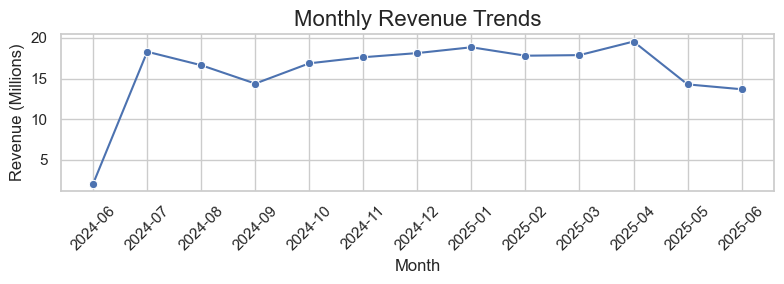

In [8]:
# Convert monthly revenue to millions
monthly_revenue_millions = monthly_revenue / 1_000_000

# Create the chart
plt.figure(figsize=(8, 3))

sns.lineplot(
    x=monthly_revenue_millions.index.astype(str),
    y=monthly_revenue_millions.values,
    marker="o"
)

plt.title("Monthly Revenue Trends", fontsize=16)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Revenue (Millions)", fontsize=12)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [9]:
# Test the conversion directly using Python
test_revenue = 208204.50

print("Original revenue:", test_revenue)
print("Divided by 1 million:", test_revenue / 1_000_000)
print("Divided by 100 thousand:", test_revenue / 100_000)

Original revenue: 208204.5
Divided by 1 million: 0.2082045
Divided by 100 thousand: 2.082045


In [10]:
# Recalculate monthly revenue in millions
monthly_revenue_millions = monthly_revenue / 1_000_000

# Display the first 3 converted values
print(monthly_revenue_millions.head(3))

# Validate the total
print("\nTotal revenue in millions:", monthly_revenue_millions.sum())

Date
2024-06     2.085205
2024-07    18.309178
2024-08    16.649315
Freq: M, Name: Revenue, dtype: float64

Total revenue in millions: 206.20997989999998


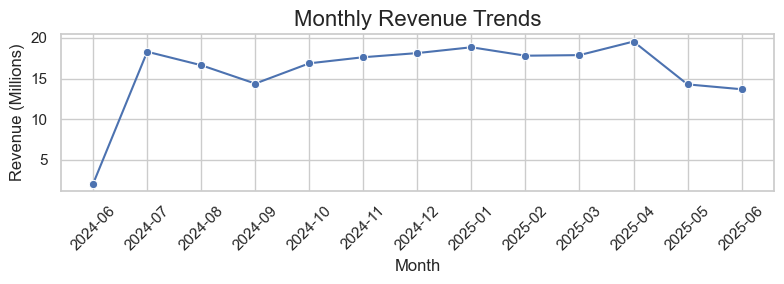

In [11]:
plt.figure(figsize=(8, 3))

sns.lineplot(
    x=monthly_revenue_millions.index.astype(str),
    y=monthly_revenue_millions.values,
    marker="o"
)

plt.title("Monthly Revenue Trends", fontsize=16)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Revenue (Millions)", fontsize=12)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
# Get the first monthly revenue value
june_revenue = monthly_revenue.iloc[0]

# Convert it directly to millions
june_in_millions = june_revenue / 1_000_000

print("Original June revenue:", repr(june_revenue))
print("Divisor:", 1_000_000)
print("June revenue in millions:", repr(june_in_millions))

# Compare with the existing converted Series
print("\nExisting converted value:", repr(monthly_revenue_millions.iloc[0]))

Original June revenue: np.float64(2085204.5)
Divisor: 1000000
June revenue in millions: np.float64(2.0852045)

Existing converted value: np.float64(2.0852045)


In [13]:
# Convert monthly revenue to millions
monthly_revenue_millions = monthly_revenue / 1_000_000

# Display the first 3 values
print(monthly_revenue_millions.head(3))

# Validate the conversion
print("\nTotal revenue (millions):", monthly_revenue_millions.sum())
print("Highest month (millions):", monthly_revenue_millions.max())
print("Lowest month (millions):", monthly_revenue_millions.min())

Date
2024-06     2.085205
2024-07    18.309178
2024-08    16.649315
Freq: M, Name: Revenue, dtype: float64

Total revenue (millions): 206.20997989999998
Highest month (millions): 19.5623475
Lowest month (millions): 2.0852045


In [14]:
# Compare the original dataset with the monthly aggregation

print("Total Revenue in dataset:", df["Revenue"].sum())

print("Total Monthly Revenue:", monthly_revenue.sum())

print("\nFirst monthly revenue value:", monthly_revenue.iloc[0])

print("\nNumber of records in dataset:", len(df))

print("Number of months:", len(monthly_revenue))

Total Revenue in dataset: 206209979.9
Total Monthly Revenue: 206209979.89999998

First monthly revenue value: 2085204.5

Number of records in dataset: 10000
Number of months: 13


In [15]:
# Set divisor to one million (10 raised to power 6)
divisor = 10**6

# Convert monthly revenue to millions
monthly_revenue_millions = monthly_revenue / divisor

# Verify
print("Divisor:", divisor)
print("First month:", monthly_revenue_millions.iloc[0])
print("Total revenue (millions):", monthly_revenue_millions.sum())

Divisor: 1000000
First month: 2.0852045
Total revenue (millions): 206.20997989999998


In [16]:
print(10**6)
print(208204.5 / 10**6)

1000000
0.2082045


In [17]:
# Rebuild monthly revenue directly from the original dataset
monthly_revenue_check = (
    df.groupby(df["Date"].dt.to_period("M"))["Revenue"]
    .sum()
)

# Convert to millions
monthly_revenue_check_millions = monthly_revenue_check / 1_000_000

# Verify the results
print("First month revenue:", monthly_revenue_check.iloc[0])
print("First month in millions:", monthly_revenue_check_millions.iloc[0])

print("\nTotal revenue:", monthly_revenue_check.sum())
print("Total revenue in millions:", monthly_revenue_check_millions.sum())

First month revenue: 2085204.5
First month in millions: 2.0852045

Total revenue: 206209979.89999998
Total revenue in millions: 206.20997989999998


In [18]:
# Correct conversion: divide by one million
monthly_revenue_check_millions = monthly_revenue_check / 1000000

# Display and verify
print("First month in millions:",
      monthly_revenue_check_millions.iloc[0])

print("Total revenue in millions:",
      monthly_revenue_check_millions.sum())

First month in millions: 2.0852045
Total revenue in millions: 206.20997989999998


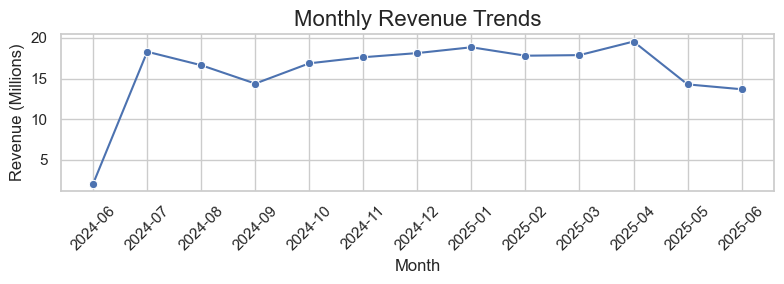

In [19]:
plt.figure(figsize=(8, 3))

sns.lineplot(
    x=monthly_revenue_check_millions.index.astype(str),
    y=monthly_revenue_check_millions.values,
    marker="o"
)

plt.title("Monthly Revenue Trends", fontsize=16)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Revenue (Millions)", fontsize=12)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [20]:
product_revenue= df.groupby('Product')['Revenue'].sum().sort_values(ascending=False)
print(product_revenue)

Product
Laptop                 85115250.00
Smartphone             37115000.00
Tablet                 28659600.00
Monitor                20264400.00
Smartwatch              7392500.00
Headphones              4535475.00
Bluetooth Speaker       3268320.00
Jacket                  2768625.00
Shoes                   2286600.00
Power Bank              2208480.00
Jeans                   1819620.00
Pants                   1631925.00
Shirt                   1098585.00
Tea                     1083417.50
Charger                 1052240.00
Skirt                    872720.00
Bralette                 654780.00
T-shirt                  473350.00
Coffee (200g)            458887.50
USB Cable                368837.50
Cap                      320505.00
Cooking Oil              249067.00
Laundry Basket           189922.50
Juice (1L)               172597.50
Energy Drink             164810.00
Deodorant                162500.00
Fruits                   162156.00
Shampoo                  139257.00
Socks       

In [22]:
# Select the top 10 products by revenue
top_10_products = product_revenue.head(10)

print(top_10_products)

Product
Laptop               85115250.0
Smartphone           37115000.0
Tablet               28659600.0
Monitor              20264400.0
Smartwatch            7392500.0
Headphones            4535475.0
Bluetooth Speaker     3268320.0
Jacket                2768625.0
Shoes                 2286600.0
Power Bank            2208480.0
Name: Revenue, dtype: float64


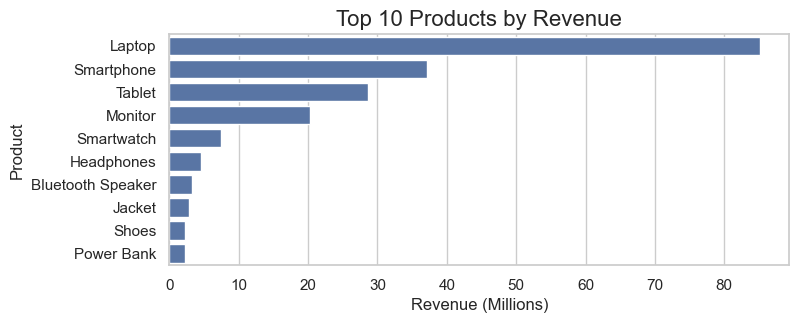

In [24]:
top_10_products_millions = top_10_products / 1_000_000

plt.figure(figsize=(8, 3))

sns.barplot(
    x=top_10_products_millions.values,
    y=top_10_products.index
)

plt.title("Top 10 Products by Revenue", fontsize=16)
plt.xlabel("Revenue (Millions)", fontsize=12)
plt.ylabel("Product", fontsize=12)

plt.show()

In [27]:
category_revenue=df.groupby('Product Category')['Revenue'].sum().sort_values(ascending=False)
print(category_revenue)

Product Category
Electronics        1.899801e+08
Clothing           1.204040e+07
Groceries          2.922136e+06
Personal Care      6.432105e+05
Household Items    4.417188e+05
Stationery         1.824175e+05
Name: Revenue, dtype: float64


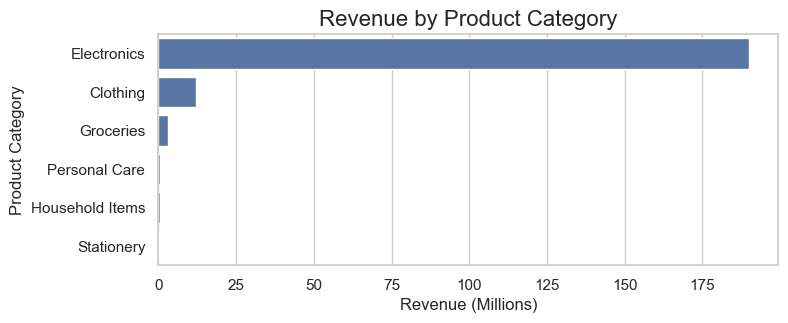

In [28]:
category_revenue_millions = category_revenue / 1_000_000    

plt.figure(figsize=(8, 3))

sns.barplot(
    x=category_revenue_millions.values,
    y=category_revenue_millions.index
)

plt.title("Revenue by Product Category", fontsize=16)
plt.xlabel("Revenue (Millions)", fontsize=12)
plt.ylabel("Product Category", fontsize=12)
plt.show()

In [29]:
revenue_city=df.groupby('City')['Revenue'].sum().sort_values(ascending=False)   
print(revenue_city) 

City
Fujairah          3259915.95
Belo Horizonte    3179008.80
Berlin            3151557.10
Cologne           3136300.90
San Jose          3106524.75
                     ...    
Dubai              612678.25
Sambalpur          585805.75
Surat              573904.00
Perth              460241.55
Ras Al Khaimah     390349.80
Name: Revenue, Length: 124, dtype: float64


In [31]:
# Calculate total revenue by city
city_revenue = (
    df.groupby("City")["Revenue"]
      .sum()
      .sort_values(ascending=False)
)

print(city_revenue)

City
Fujairah          3259915.95
Belo Horizonte    3179008.80
Berlin            3151557.10
Cologne           3136300.90
San Jose          3106524.75
                     ...    
Dubai              612678.25
Sambalpur          585805.75
Surat              573904.00
Perth              460241.55
Ras Al Khaimah     390349.80
Name: Revenue, Length: 124, dtype: float64


In [33]:
# Select the top 10 cities by revenue
top_10_cities = city_revenue.head(10)

print(top_10_cities)

City
Fujairah          3.259916
Belo Horizonte    3.179009
Berlin            3.151557
Cologne           3.136301
San Jose          3.106525
Dallas            2.669743
Adelaide          2.599472
Sheffield         2.591758
Rewa              2.560729
Manaus            2.528170
Name: Revenue, dtype: float64


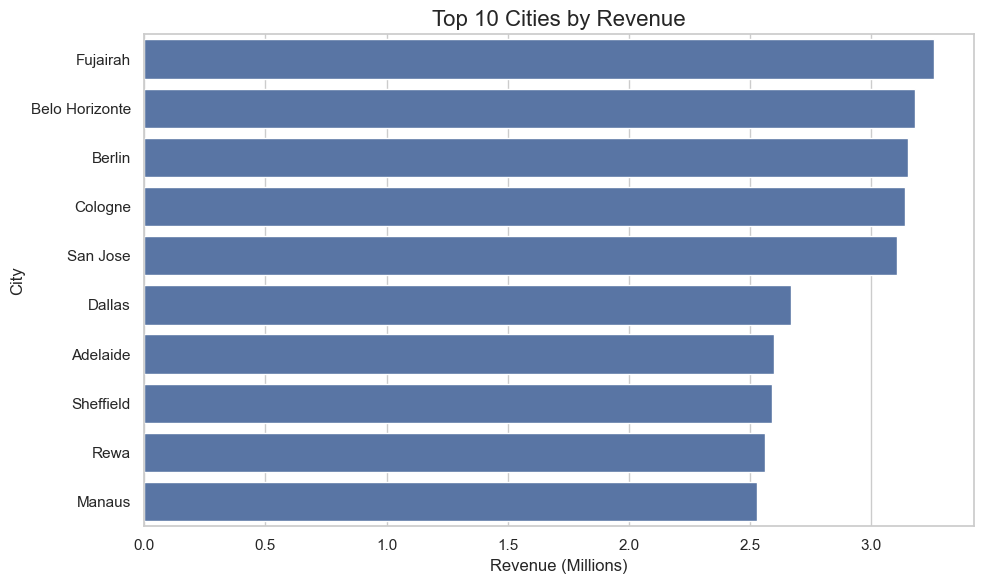

In [34]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_10_cities.values,
    y=top_10_cities.index
)

plt.title("Top 10 Cities by Revenue", fontsize=16)
plt.xlabel("Revenue (Millions)", fontsize=12)
plt.ylabel("City", fontsize=12)

plt.tight_layout()
plt.show() 

In [37]:
revenue_by_customer=df.groupby('Customer Type')['Revenue'].sum().sort_values(ascending=False)
print(revenue_by_customer)   

Customer Type
Normal    140850190.7
Member     65359789.2
Name: Revenue, dtype: float64


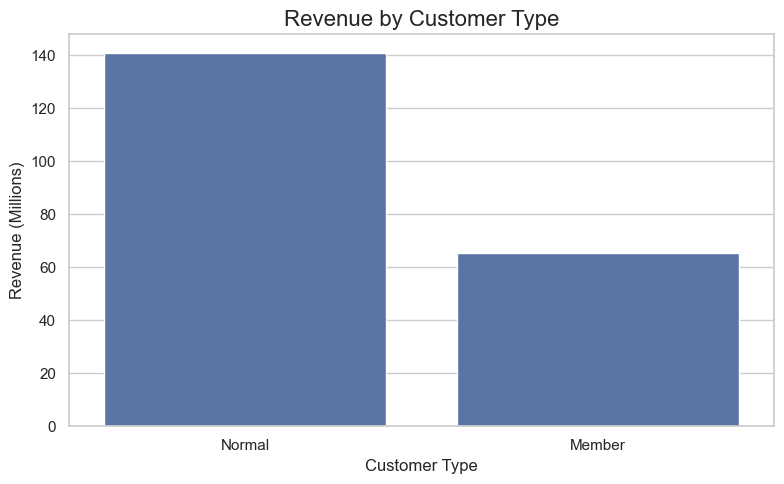

In [38]:
# Convert revenue to millions
customer_type_revenue_millions = revenue_by_customer / 1_000_000

# Create the chart
plt.figure(figsize=(8, 5))

sns.barplot(
    x=customer_type_revenue_millions.index,
    y=customer_type_revenue_millions.values
)

plt.title("Revenue by Customer Type", fontsize=16)
plt.xlabel("Customer Type", fontsize=12)
plt.ylabel("Revenue (Millions)", fontsize=12)

plt.tight_layout()
plt.show()

In [39]:
# Calculate total profit by product category
category_profit = (
    df.groupby("Product Category")["Profit"]
      .sum()
      .sort_values(ascending=False)
)

print(category_profit)

Product Category
Electronics        40394802.50
Clothing            2558895.00
Groceries            620993.70
Personal Care        135670.50
Household Items       95303.75
Stationery            39054.45
Name: Profit, dtype: float64


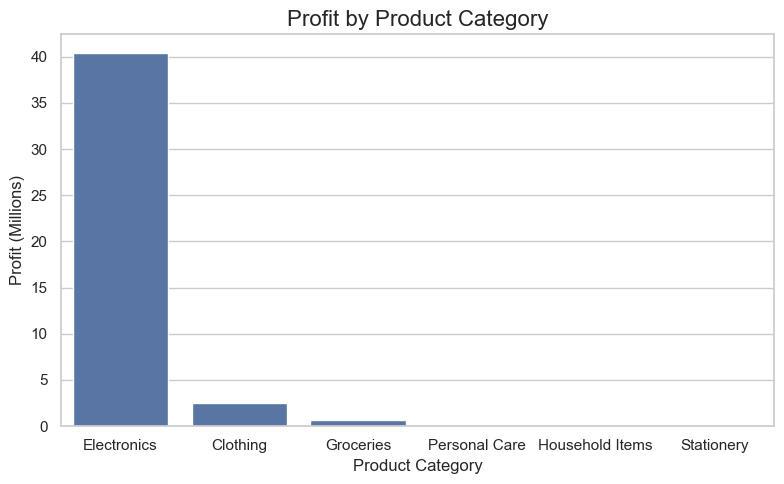

In [40]:
profit_by_category_millions = category_profit / 1_000_000

plt.figure(figsize=(8, 5))

sns.barplot(    
    x=profit_by_category_millions.index,
    y=profit_by_category_millions.values

)

plt.title("Profit by Product Category", fontsize=16)
plt.xlabel("Product Category", fontsize=12)
plt.ylabel("Profit (Millions)", fontsize=12)

plt.tight_layout()  
plt.show()  

In [41]:
category_margin = (
    df.groupby("Product Category")[["Revenue", "Profit"]]
      .sum()
)

category_margin["Profit Margin (%)"] = (
    category_margin["Profit"] /
    category_margin["Revenue"]
) * 100

category_margin = category_margin.sort_values(
    "Profit Margin (%)",
    ascending=False
)

print(category_margin)

                       Revenue       Profit  Profit Margin (%)
Product Category                                              
Household Items   4.417188e+05     95303.75          21.575663
Stationery        1.824175e+05     39054.45          21.409383
Electronics       1.899801e+08  40394802.50          21.262649
Clothing          1.204040e+07   2558895.00          21.252583
Groceries         2.922136e+06    620993.70          21.251364
Personal Care     6.432105e+05    135670.50          21.092706


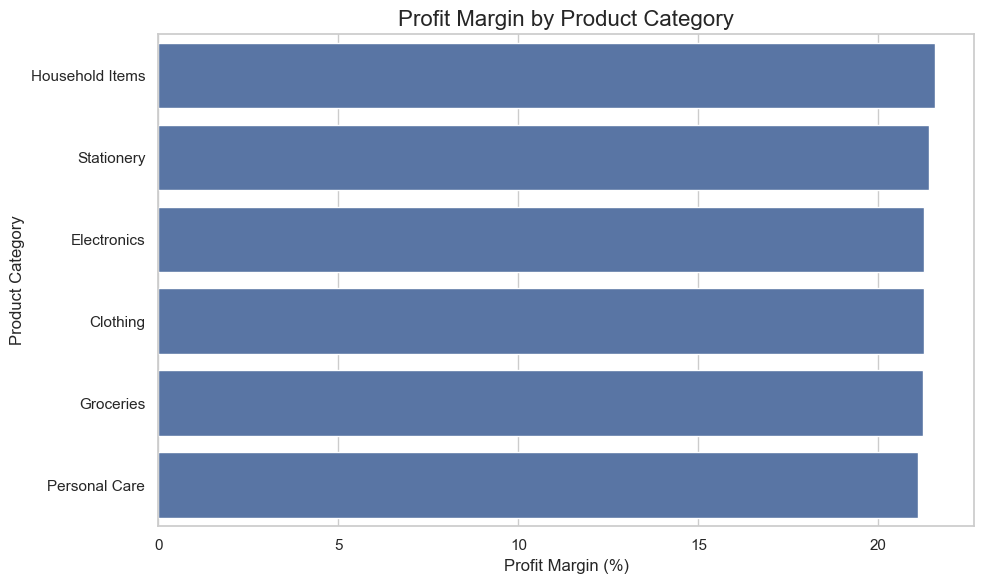

In [42]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_margin["Profit Margin (%)"].values,
    y=category_margin.index
)

plt.title("Profit Margin by Product Category", fontsize=16)
plt.xlabel("Profit Margin (%)", fontsize=12)
plt.ylabel("Product Category", fontsize=12)

plt.tight_layout()
plt.show()

In [43]:
product_performance = (
    df.groupby("Product")[["Revenue", "Profit"]]
      .sum()
      .sort_values("Revenue", ascending=False)
)

print(product_performance.head(10))

                      Revenue      Profit
Product                                  
Laptop             85115250.0  18070250.0
Smartphone         37115000.0   7915000.0
Tablet             28659600.0   6105600.0
Monitor            20264400.0   4304400.0
Smartwatch          7392500.0   1562500.0
Headphones          4535475.0    979475.0
Bluetooth Speaker   3268320.0    685520.0
Jacket              2768625.0    593625.0
Shoes               2286600.0    478600.0
Power Bank          2208480.0    469680.0


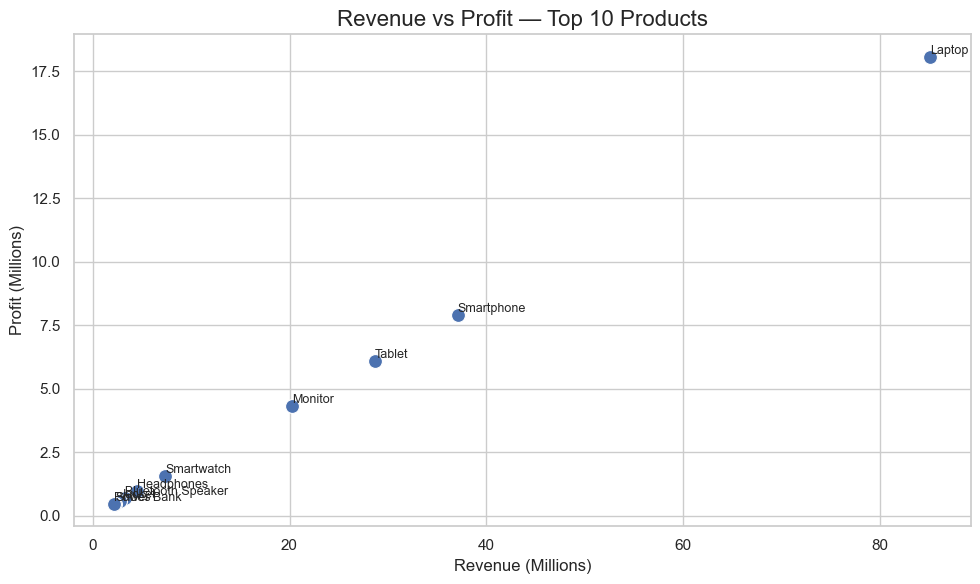

In [46]:

# Use the top 10 products by revenue
top_10_performance = product_performance.head(10)

# Convert to millions
top_10_performance_millions = top_10_performance / 1_000_000

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=top_10_performance_millions["Revenue"],
    y=top_10_performance_millions["Profit"],
    s=100
)

# Add product names
for product, row in top_10_performance_millions.iterrows():
    plt.text(
        row["Revenue"],
        row["Profit"],
        product,
        fontsize=9,
        ha="left",
        va="bottom"
    )

plt.title("Revenue vs Profit — Top 10 Products", fontsize=16)
plt.xlabel("Revenue (Millions)", fontsize=12)
plt.ylabel("Profit (Millions)", fontsize=12)

plt.tight_layout()
plt.show()